# **A prototype module for verifying the ethical and legal admissibility of decisions of an autonomous AI director**

A human director applies open standards ("reasonableness," "good faith") to the situation, while an autonomous AI system only sees what is formally written. Therefore, the four standards are translated into mathematical constraints, and the admissibility of a solution is verified by a single formula.

$$D^*(t)=\{\,d\in D:\; F(d)\ge\theta \;\wedge\; E(d)=\text{true} \;\wedge\; d\in I_t \;\wedge\; R(d)\le R^{\max}\,\}$$

**Contents**


| # | Standard | Mathematical representation |
|---|---|---|
| 1 | Justice | Vector of metrics $F(d)$ and thresholds $\theta$
| 2 | Equality | Counterfactual condition, $PSE$ over inadmissible paths
| 3 | Decision interval | Spatial (admissible range) $I$ and temporal $T$ intervals
| 4 | Acceptable risk | Risk vector by stakeholders $R(d)$
| 5 | Integration| Admissibility condition $D^*(t)$, escalation, Theorem 2
| 6 | Extensibility | A new standard is added by conjunction

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Fix randomness for reproducibility
rng = np.random.default_rng(42)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

### Theorem 1: The three fairness criteria are incompatible (Kleinberg et al.; Chouldechova)

If the base rates of positive outcomes differ across groups, no classifier can simultaneously provide:

1. **calibration** — among those receiving a score of $s$, the proportion of truly positive outcomes is equal to $s$ in each group;
2. **balance for the positive class** — the average score of truly positive outcomes is the same across groups;
3. **balance for the negative class** — the same for truly negative outcomes.

Below, we construct a classifier calibrated *by construction* and see balance discontinuities; attempting to balance the balance breaks the calibration. The conclusion: the instruction "make fair decisions" without specifying a criterion is computationally meaningless — the choice of criterion must be explicit and documented.

In [ ]:
"""This function creates a single protected group for demonstrating Theorem 1 — n people,
each with a classifier score and a true outcome, where the classifier is perfectly calibrated by construction.
The idea behind this approach is that we don't train any model, but rather immediately construct the best case
for the theorem — a perfectly calibrated classifier. If even this classifier can't equalize errors between groups
with different base rates, then no real classifier can, which is precisely what the theorem states."""
def calibrated_group(n, base_rate, rng, concentration=4):
    """Scores s ~ Beta with average base_rate; outcome Y ~ Bernoulli(s).
    Then P(Y=1 | S=s) = s — calibration is by construction.
    concentration is the sum of the parameters of the beta distribution, κ = α + β."""
    s = rng.beta(base_rate * concentration, (1 - base_rate) * concentration, size=n)
    y = (rng.random(n) < s).astype(int)
    return s, y


#Calculate rate by group
def rate_by_group(values, groups):
    return pd.Series(np.asarray(values)).groupby(np.asarray(groups)).mean()


def three_conditions(s, y, g, bins=10):
    """The degree of violation of the three conditions of Theorem 1 (0 = condition is satisfied)."""
    s, y, g = map(np.asarray, (s, y, g))
    edges = np.linspace(0, 1, bins + 1)
    cal_err = 0.0
    for grp in np.unique(g):                         # 1) calibration within each group
        m = g == grp
        b = np.clip(np.digitize(s[m], edges) - 1, 0, bins - 1)
        for k in range(bins):
            mk = b == k
            if mk.sum() >= 50:
                cal_err = max(cal_err, abs(y[m][mk].mean() - s[m][mk].mean()))
    pos = rate_by_group(s[y == 1], g[y == 1])        # 2) balance for positive class
    neg = rate_by_group(s[y == 0], g[y == 0])        # 3) balance for negative class
    return pd.Series({"calibration error": cal_err,
                      "balance gap, class Y=1": pos.max() - pos.min(),
                      "balance gap, class Y=0": neg.max() - neg.min()})


n = 20_000
s_a, y_a = calibrated_group(n, base_rate=0.30, rng=rng)   # group A: base share 30%
s_b, y_b = calibrated_group(n, base_rate=0.60, rng=rng)   # group B: base rate 60%
s, y, g = np.r_[s_a, s_b], np.r_[y_a, y_b], np.r_[["a"] * n, ["b"] * n]

results = {"1. calibrated classifier": three_conditions(s, y, g)}

# We try to “fix” the balance: we monotonically compress the points of group b (s -> s^k), selecting k
best_k = min(np.linspace(1, 4, 61),
             key=lambda k: three_conditions(np.r_[s_a, s_b ** k], y, g)["balance gap, class Y=1"])
results[f"2. after equalizing the balance (k = {best_k:.2f})"] = three_conditions(np.r_[s_a, s_b ** best_k], y, g)

# Degenerate cases
results["3. constant score for all"] = three_conditions(np.full(2 * n, y.mean()), y, g)
results["4. ideal predictor (s = y)"] = three_conditions(y.astype(float), y, g)

pd.DataFrame(results).T.round(3)

,calibration error,"balance gap, class Y=1","balance gap, class Y=0"
1. calibrated classifier,0.013,0.241,0.242
2. after equalizing the balance (k = 2.50),0.330,0.003,0.024
3. constant score for all,0.152,0.000,0.000
4. ideal predictor (s = y),0.000,0.000,0.000


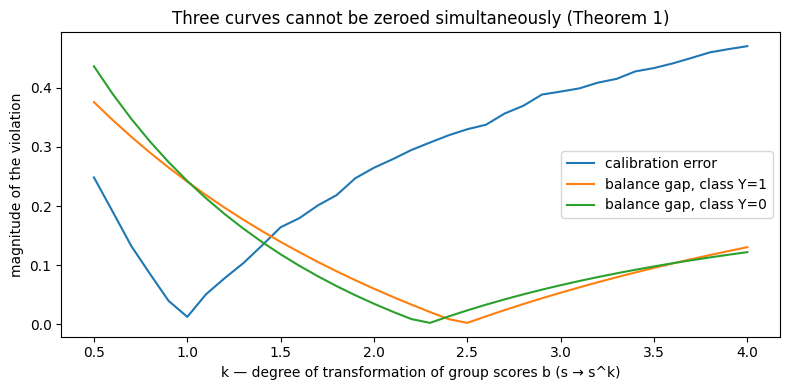

In [ ]:
# Demonstrate the three fairness criteria are incompatible
ks = np.linspace(0.5, 4, 36)
sweep = pd.DataFrame([three_conditions(np.r_[s_a, s_b ** k], y, g) for k in ks], index=ks)
ax = sweep.plot(figsize=(8, 4))
ax.set_xlabel("k — degree of transformation of group scores b (s → s^k)")
ax.set_ylabel("magnitude of the violation")
ax.set_title("Three curves cannot be zeroed simultaneously (Theorem 1)")
plt.tight_layout()
plt.show()

Note: for different base rates, the constant score breaks the calibration within groups, while all three conditions are satisfied only by the ideal predictor (the second degenerate case in Kleinberg et al. - equal base rates).

# **To test the legal axioms we will use the UCI Adult dataset [Adult](https://archive.ics.uci.edu/dataset/2/adult)**

**Assumptions:**

Performance = education + hours per week; income is excluded because it carries the gender gap.

Prior position level is an ordinal scale by occupation; tenure is “potential experience” (age − years of schooling − 6).

The structural equation of the mediator is estimated by linear regression on the data.

y_true and prior_level are both derived from occupation, which is why policies that use the prior position show a very high TPR.

Thresholds, the tolerance ε, risk limits and loss weights are illustrative parameters standing in for “inputs supplied by law”, not the norms of any actual jurisdiction.

In [ ]:
# Building the notebook's df from the UCI Adult dataset (https://archive.ics.uci.edu/dataset/2/adult)

# Gender labels
MALE, FEMALE = "Male", "Female"

COLUMNS = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
           "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
           "hours_per_week", "native_country", "income"]


# Load Adult
def load_adult(path=None):
    """Loads Adult: from a local file (adult.data / adult-all.csv), via the official ucimlrepo package
    (pip install ucimlrepo), or directly from archive.ics.uci.edu. Returns the raw table, 48,842 x 15."""
    if path is not None:
        return pd.read_csv(path, header=None, names=COLUMNS, skipinitialspace=True, na_values="?",
                           comment="|")
    try:
        from ucimlrepo import fetch_ucirepo
        adult = fetch_ucirepo(id=2)
        raw = pd.concat([adult.data.features, adult.data.targets], axis=1)
        raw.columns = [c.replace("-", "_") for c in raw.columns]
        return raw
    except ImportError:
        base = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
        train = pd.read_csv(base + "adult.data", header=None, names=COLUMNS, skipinitialspace=True, na_values="?")
        test = pd.read_csv(base + "adult.test", header=None, names=COLUMNS, skipinitialspace=True, na_values="?",
                           skiprows=1)
        return pd.concat([train, test], ignore_index=True)


# Job level by occupation (1 = lowest, 5 = highest). The order follows the share of >50K income within each
# occupation in the dataset itself; edit the map to match your own "grade" structure if needed.
OCCUPATION_LEVEL = {
    "Exec-managerial": 5, "Prof-specialty": 5,
    "Protective-serv": 4, "Tech-support": 4, "Sales": 4,
    "Craft-repair": 3, "Transport-moving": 3,
    "Adm-clerical": 2, "Machine-op-inspct": 2, "Farming-fishing": 2, "Armed-Forces": 2,
    "Handlers-cleaners": 1, "Other-service": 1, "Priv-house-serv": 1,
}


# Standardizes a variable: it subtracts the mean and divides by the standard deviation,
# so the result has mean 0 and standard deviation 1
def zscore(x):
    x = np.asarray(x, dtype=float)
    return (x - x.mean()) / x.std()


# Build the dataframe
def build_df(raw, sample_n=None, seed=42):
    """Builds df with the notebook's columns: gender, age, age_group, performance, tenure, prior_level, u_lvl, y_true."""
    r = raw.copy()
    for c in ["sex", "occupation", "income"]:                     # ' Male', '>50K.' -> 'Male', '>50K'
        r[c] = r[c].astype("string").str.strip().str.rstrip(".")
    r = r[r.occupation.notna() & (r.occupation != "?")]          # occupation is needed for prior_level and y_true
    r = r[r.sex.isin(["Male", "Female"])]

    out = pd.DataFrame(index=r.index)
    # A1 — gender; A2 — age and age group
    out["gender"] = np.where(r.sex == "Male", MALE, FEMALE)
    out["age"] = r.age.astype(int)
    out["age_group"] = np.where(out.age < 40, "<40", "40+")


    # X1 — performance WITHOUT income: qualification (years of education) plus workload (hours per week).
    # Income in Adult is strongly gender-dependent, so using it as an "admissible" characteristic would
    # reproduce the gender gap; education and hours carry much less of it. Standardized (mean 0, std 1).
    out["performance"] = zscore(zscore(r.education_num.astype(float)) + 0.25 * zscore(r.hours_per_week))

    # X2 — tenure: not available in Adult; the standard "potential experience" proxy = age − years of schooling − 6
    out["tenure"] = np.clip(out.age - r.education_num.astype(int) - 6, 0, None)

    # Mediator — level of the previous position: ordinal scale by occupation, standardized
    out["prior_level"] = zscore(r.occupation.map(OCCUPATION_LEVEL).astype(float))

    # Y — "deserves promotion": holds an executive/managerial position
    out["y_true"] = (r.occupation == "Exec-managerial").astype(int)

    out["occupation"], out["income"] = r.occupation, r.income     # for reference only, not used in the checks
    out = out.reset_index(drop=True)
    if sample_n is not None:
        out = out.sample(n=sample_n, random_state=seed).reset_index(drop=True)
    return out


raw = load_adult()            # load_adult("adult-all.csv") — if the file was downloaded manually
df = build_df(raw)            # build_df(raw, sample_n=5000) — if a smaller sample is preferred

# The structural equation of the mediator is ESTIMATED from the data (in the synthetic world it was hand-set):
# prior_level = a + b·performance + bias·[male] + u_lvl.  The residual u_lvl is kept — it is needed for the
# counterfactual computations (abduction step).
X = np.column_stack([np.ones(len(df)), df.performance, (df.gender == MALE).astype(float)])
A_HAT, B_HAT, BIAS_HAT = np.linalg.lstsq(X, df.prior_level.values, rcond=None)[0]
df["u_lvl"] = df.prior_level - X @ np.array([A_HAT, B_HAT, BIAS_HAT])


def prior_level_fn(gender, performance, u_lvl, bias=BIAS_HAT):
    """Structural equation of the mediator M estimated from the data. Same signature as in the notebook,
    so counterfactual() and path_specific_effect() work without changes."""
    return A_HAT + B_HAT * np.asarray(performance, dtype=float) + bias * (np.asarray(gender) == MALE) \
        + np.asarray(u_lvl, dtype=float)


N = len(df)
print(f"{N} people; male share {np.mean(df.gender == MALE):.0%}; "
      f"executives (y_true=1): {df.y_true.mean():.0%}")
print("Share of >50K by gender:", df.groupby("gender", observed=True).income.apply(lambda s: (s == '>50K').mean()).round(3).to_dict())
print("Share of executives by gender:", df.groupby("gender", observed=True).y_true.mean().round(3).to_dict())
print(f"Estimated equation: prior_level = {A_HAT:.3f} + {B_HAT:.3f}·performance + {BIAS_HAT:.3f}·[M] + u_lvl")
assert np.allclose(prior_level_fn(df.gender, df.performance, df.u_lvl), df.prior_level)  # the equation reproduces the data
df.head()

46033 people; male share 68%; executives (y_true=1): 13%
Share of >50K by gender: {'Female': 0.114, 'Male': 0.313}
Share of executives by gender: {'Female': 0.117, 'Male': 0.139}
Estimated equation: prior_level = -0.096 + 0.491·performance + 0.143·[M] + u_lvl


,gender,age,age_group,performance,tenure,prior_level,y_true,occupation,income,u_lvl
0,Male,39,<40,1.032,20,-0.816,0,Adm-clerical,<=50K,-1.369
1,Male,50,40+,0.505,31,1.276,1,Exec-managerial,<=50K,0.981
2,Male,38,<40,-0.432,23,-1.513,0,Handlers-cleaners,<=50K,-1.347
3,Male,53,40+,-1.164,40,-1.513,0,Handlers-cleaners,<=50K,-0.987
4,Female,28,<40,1.032,9,1.276,0,Prof-specialty,<=50K,0.865


In [ ]:
RATE = 0.40   # the budget allows for 40% of employee promotions

# Biased policy
def policy_biased(d):
    """Directly exploits gender (+0.4 for men) and previous position: both inadmissible paths are involved."""
    return d.performance + 0.7 * d.prior_level + 0.4 * (d.gender == MALE)

# Justice through unawareness
def policy_unaware(d):
    """ "Justice through unawareness": gender is not used, but the proxy remains—the previous position."""
    return d.performance + 0.7 * d.prior_level

# Only admissible paths
def policy_causal(d):
    """Only admissible characteristics: performance and tenure."""
    return d.performance + 0.005 * d.tenure

# Threshold for a positive decision
def threshold_for(score, rate=RATE):
    """The selection threshold at which the rate share receives a positive decision."""
    return np.quantile(score, 1 - rate)

# Promote
def decide(score, threshold):
    """Decision d ∈ {0, 1}: 1 — promote."""
    return (np.asarray(score) >= threshold).astype(int)

# Run policy
def run_policy(policy, d, rate=RATE):
    """Applies a policy to data; returns decisions and the threshold used."""
    s = policy(d)
    thr = threshold_for(s, rate)
    return decide(s, thr), thr


POLICIES = {"biased  (direct discrimination)": policy_biased,
            "unaware (the gender is not used, but there is a proxy)": policy_unaware,
            "causal  (only admissible attributes)": policy_causal}

pd.DataFrame({name: pd.Series(run_policy(p, df)[0]).groupby(df.gender.values).mean()
              for name, p in POLICIES.items()}).T.rename(columns=lambda c: f"proportion of promoted: {c}")

,proportion of promoted: Female,proportion of promoted: Male
biased (direct discrimination),0.291,0.452
"unaware (the gender is not used, but there is a proxy)",0.365,0.417
causal (only admissible attributes),0.352,0.423


## 1. Fairness: the vector $F(d)$ and the thresholds $\theta$

Fairness is a **group, statistical** property: how decisions are distributed among protected groups. For each protected feature $A_j$, $\varphi_j(d)\in[0,1]$ is calculated—the degree to which the *selected* criterion is met—and the vector $F(d)=(\varphi_1,\dots,\varphi_m)$ is assembled. A decision passes verification if $F(d)\ge\theta$ componentwise.

The metric to use for each feature (statistical parity, equal opportunity, calibration, etc.) and the threshold are **not part of the formula, but a parameter** determined by applicable law and company policy (Fairness Axiom 4). Below are three metrics from Table 1 and two illustrative “jurisdictions” with different parameters.

In [ ]:
#Calculate rate by group
def rate_by_group(values, groups):
    return pd.Series(np.asarray(values)).groupby(np.asarray(groups)).mean()


# Statisitcal parity
def statistical_parity(y_hat, y_true, g):
    """φ = min(proportion of positive decisions) / max(...) by groups - “four-fifths rule”."""
    r = rate_by_group(y_hat, g)
    return r.min() / r.max()

# Equal opportunity
def equal_opportunity(y_hat, y_true, g):
    """φ = 1 − |TPR_a − TPR_b|: among those who are truly worthy, the proportion of those promoted is the same
     across groups."""
    m = np.asarray(y_true) == 1
    tpr = rate_by_group(np.asarray(y_hat)[m], np.asarray(g)[m])
    return 1 - (tpr.max() - tpr.min())

# Predictive parity
def predictive_parity(y_hat, y_true, g):
    """φ = 1 − |PPV_a − PPV_b|: among the promoted, the proportion of those who are truly worthy is the same
    (calibration class)."""
    m = np.asarray(y_hat) == 1
    ppv = rate_by_group(np.asarray(y_true)[m], np.asarray(g)[m])
    return 1 - (ppv.max() - ppv.min())

# Metrics used
METRICS = {"statistical_parity": statistical_parity,
           "equal_opportunity": equal_opportunity,
           "predictive_parity": predictive_parity}

# Parameters that "the law supplies": feature -> (metric, threshold θ). Values ​​are an example.
JURISDICTIONS = {
    "Jurisdiction A": {"gender": ("statistical_parity", 0.80), "age_group": ("statistical_parity", 0.70)},
    "Jurisdiction B": {"gender": ("equal_opportunity", 0.90),  "age_group": ("predictive_parity", 0.90)},
}


# Justice vector
def justice_vector(d, y_hat, config):
    """F(d) = (φ_1, …, φ_m): one component for each protected attribute from config."""
    return pd.Series({attr: METRICS[metric](y_hat, d.y_true, d[attr])
                      for attr, (metric, _) in config.items()})

# Thresholds
def thresholds(config):
    return pd.Series({attr: thr for attr, (_, thr) in config.items()})


# Justice check
def justice_ok(F, config):
    """Checking F(d) ≥ θ componentwise."""
    return bool((F >= thresholds(config)).all())


# Justice results table
def justice_table(config, d=df):
    rows = {}
    for name, pol in POLICIES.items():
        y_hat, _ = run_policy(pol, d)
        F = justice_vector(d, y_hat, config)
        rows[name] = {**{f"φ({a})": v for a, v in F.items()}, "F ≥ θ": justice_ok(F, config)}
    return pd.DataFrame(rows).T

# Justice for Jurisdiction A
config = JURISDICTIONS["Jurisdiction A"]
print("Thresholds θ:", thresholds(config).to_dict())
justice_table(config)

Thresholds θ: {'gender': 0.8, 'age_group': 0.7}


,φ(gender),φ(age_group),F ≥ θ
biased (direct discrimination),0.642,0.769,False
"unaware (the gender is not used, but there is a proxy)",0.876,0.78,True
causal (only admissible attributes),0.831,0.764,True


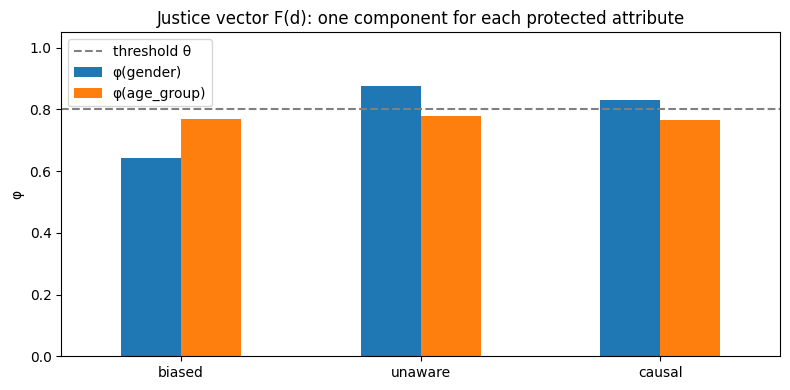

In [ ]:
# Demonstrate Justice vector for Jurisdiction A
tab = justice_table(config).drop(columns="F ≥ θ").astype(float)
tab.index = [name.split()[0] for name in tab.index]
ax = tab.plot(kind="bar", figsize=(8, 4), rot=0)
ax.axhline(thresholds(config).iloc[0], ls="--", color="gray", label="threshold θ")
ax.set_ylim(0, 1.05)
ax.set_ylabel("φ")
ax.set_title("Justice vector F(d): one component for each protected attribute")
ax.legend()
plt.tight_layout()
plt.show()

### Fairness Axiom 4: same structure, different parameters

The verification code doesn't change, only the dictionary of parameters changes: the set of features, the metric for each feature, and the thresholds. This is what ensures jurisdictional neutrality: one architecture, different legal regimes.

In [ ]:
# Justice for Jurisdiction B
print("Thresholds θ:", thresholds(JURISDICTIONS["Jurisdiction B"]).to_dict())
justice_table(JURISDICTIONS["Jurisdiction B"])

Thresholds θ: {'gender': 0.9, 'age_group': 0.9}


,φ(gender),φ(age_group),F ≥ θ
biased (direct discrimination),0.824,0.94,False
"unaware (the gender is not used, but there is a proxy)",0.991,0.936,True
causal (only admissible attributes),0.869,0.937,False


Note 1: Fairness Axiom 4: the same causal policy is fair under statistical parity (A) and unfair under equal opportunity (B)—the verdict depends on the metric chosen by the law.

Note 2: Theorem 1: none of the three policies passes both jurisdictions because the criteria are incompatible at different base rates (executives make up 13.9% of men and 11.7% of women).

### Fairness Axioms 1–3

- **Fairness 1 (non-emptiness of the admissible set)** — there is always at least one solution with $F(d)\ge\theta$: the "escalate to a human director" option satisfies the thresholds by definition.
- **Fairness 2 (Constrained Pareto Improvement)** — $d\prec d'$, if $d'$ improves the situation of at least one stakeholder, harms no one, and $F(d')\ge\theta$. Shareholder gains at the expense of employee discrimination are not considered a Pareto improvement.
- **Fairness 3 (non-exacerbation of unfairness)** — relative to the status quo $d_0$: $\Delta\varphi_j=\varphi_j(d)-\varphi_j(d_0)\ge 0$ for all $j$.

In [ ]:
# Fairness thresholds
theta = thresholds(config)

# Fairness 1: Escalation by definition yields φ = 1 for all features → the feasible set is not empty
F_escalate = pd.Series(1.0, index=theta.index)
print("Escalation is satisfying F ≥ θ:", justice_ok(F_escalate, config))

# Fairness 3: status quo d0 — last year's (manual) process, which took into account gender,
# previous position, and length of service
def policy_status_quo(d):
    return d.performance + 0.7 * d.prior_level + 0.2 * (d.gender == MALE) + 0.005 * d.tenure

# Check the current level of justice
F0 = justice_vector(df, run_policy(policy_status_quo, df)[0], config)
print("F(d0) status quo:", F0.round(3).to_dict())
delta = pd.DataFrame({name: justice_vector(df, run_policy(p, df)[0], config) - F0
                      for name, p in POLICIES.items()}).T
delta.columns = [f"Δφ({c})" for c in delta.columns]
delta["does not aggravate injustice (Δφ ≥ 0)"] = (delta >= -1e-9).all(axis=1)
delta

Escalation is satisfying F ≥ θ: True
F(d0) status quo: {'gender': 0.749, 'age_group': 0.722}


,Δφ(gender),Δφ(age_group),does not aggravate injustice (Δφ ≥ 0)
biased (direct discrimination),-0.107,0.048,False
"unaware (the gender is not used, but there is a proxy)",0.127,0.058,True
causal (only admissible attributes),0.082,0.043,True


Create example utilities functions for stakeholders

In [ ]:
# Create example utilities functions for stakeholders
def utilities(y_hat, d=df):
    """Stakeholder utilities u_i(d) are conditional, for illustration purposes:
    shareholders—the average performance of promoted employees; employees—the proportion of deserving employees who received a promotion;
    the regulator—the smallest component of the equity vector."""
    return pd.Series({"shareholders": d.performance.values[y_hat == 1].mean(),
                      "employees": y_hat[d.y_true.values == 1].mean(),
                      "regulator": justice_vector(d, y_hat, config).min()})


def pareto_better(new, old):
    """d_old ≺ d_new: some are better off, no one is worse off AND F(d_new) ≥ θ (Fairness Axiom 2)."""
    y_new, y_old = run_policy(new, df)[0], run_policy(old, df)[0]
    u_new, u_old = utilities(y_new), utilities(y_old)
    improves = bool((u_new > u_old).any() and (u_new >= u_old - 1e-9).all())
    return improves and justice_ok(justice_vector(df, y_new, config), config)


print("Stakeholder benefits u_i(d):")
print(pd.DataFrame({name: utilities(run_policy(p, df)[0]) for name, p in POLICIES.items()}).T, "\n")

names = list(POLICIES)
print("Is the decision in ROW a Pareto improvement (with a fairness constraint) relative to the solution in COLUMN?:")
pd.DataFrame([[pareto_better(POLICIES[a], POLICIES[b]) if a != b else "—" for b in names] for a in names],
             index=names, columns=names)

Stakeholder benefits u_i(d):
                                                    shareholders  employees  regulator
biased  (direct discrimination)                            0.844      0.918      0.642
unaware (the gender is not used, but there is a...         0.845      0.954      0.780
causal  (only admissible attributes)                       0.951      0.669      0.764 

Is the decision in ROW a Pareto improvement (with a fairness constraint) relative to the solution in COLUMN?:


,biased (direct discrimination),"unaware (the gender is not used, but there is a proxy)",causal (only admissible attributes)
biased (direct discrimination),—,False,False
"unaware (the gender is not used, but there is a proxy)",True,—,False
causal (only admissible attributes),False,False,—


What can be seen in the utilities:

Shareholders (average performance of promoted individuals) — causal is the best, 0.951: it selects based on performance;
Employees (the proportion of actual executives promoted, i.e., TPR) — unaware 0.954 and biased 0.918 versus 0.669 for causal. There's a leak at work here: prior_level and y_true are derived from the same occupation column, so policies that use the previous position "guess" executives almost flawlessly;
Regulator (the smallest component of $F$) — unaware 0.780, causal 0.764, biased 0.642.

Hence the matrix: unaware dominates biased in all three and passes $F\ge\theta$ → the only True value. The causal isn't a Pareto improvement relative to anyone: it wins for shareholders but loses to employees—a classic tradeoff where the Pareto criterion is silent. Fairness 2 doesn't rank such pairs at all; it merely prohibits considering something purchased at the expense of fairness an improvement.

This fits well with the logic of the article: none of the four blocks does all the work alone. Biased is cut off by the Fairness and Fairness 3 thresholds; unaware performs best in both Pareto and fairness terms, and is cut off only by the Equality block (PSE 0.023 > ε). So, in the final $D^*(t)$, causal remains, although it doesn't "dominate" in terms of utility.

Note: the high TPR of unaware/biased is largely an artifact of the fact that both "previous position" and "worthy of promotion" are derived from a single variable.

## 2. Equality: Causal Formalization (Definitions 3–5)

Equality is an **individual** property: will two identical people receive the same decision, and if not, through what causal mechanism. Two legal doctrines are translated into the language of causal paths in SCM:

| Doctrine | In SCM | How we test |
|---|---|---|
| Disparate treatment (direct discrimination) | direct path $A\to Y$ | change $A$ at the model input, hold the rest fixed |
| Disparate impact (indirect) | path through the "legacy" mediator $A\to M\to Y$ | change $A$ and recalculate only the inadmissible mediators |

Counterfactual condition (Definition 3): $Y(A\leftarrow a,X\leftarrow x)=Y(A\leftarrow a',X\leftarrow x)$. A complete ban on influence is sometimes unnecessary, so paths are divided into admissible $P_{adm}$ and inadmissible $P_{inadm}$ (Definition 4), and the constraint has the form $PSE_{inadm}(a,a')\le\varepsilon$ (Definition 5). Here $PSE$ (path-specific effect) is computed as the proportion of people whose decision would change if $A$ were changed along inadmissible paths (the selection threshold is fixed).

In [ ]:
INADMISSIBLE_MEDIATORS = ["prior_level"]   # P_inadm: path classification is a parameter that is set by a law/policy
EPS = 0.02                                 # tolerance ε (Definition 5)


# The result is a counterfactual gender column, where every man has become a
# woman and every woman has become a man.
def flip(gender):
    return np.where(np.asarray(gender) == MALE, FEMALE, MALE)


# Calculate counterfactual
def counterfactual(d, flip_direct=True, flip_mediators=()):
    """The counterfactual world is "the same person, but with a different value of A."
    Pearl's steps: abduction (take noise U from the actual world) → intervention A ← a′ →
    prediction (recalculate only the mediators assigned to the specified paths)."""
    cf = d.copy()
    a_prime = flip(d.gender)
    if "prior_level" in flip_mediators:
        cf["prior_level"] = prior_level_fn(a_prime, d.performance, d.u_lvl)
    if flip_direct:
        cf["gender"] = a_prime
    return cf


# Check PSE
def path_specific_effect(policy, d, flip_direct, flip_mediators):
    """PSE: the proportion of people whose decision would change if A were to change along the specified paths."""
    s = policy(d)
    thr = threshold_for(s)
    y_fact = decide(s, thr)
    y_cf = decide(policy(counterfactual(d, flip_direct, flip_mediators)), thr)
    return float(np.mean(y_fact != y_cf))


# Report
def equality_report(policy, d=df, inadmissible=INADMISSIBLE_MEDIATORS, eps=EPS):
    direct   = path_specific_effect(policy, d, flip_direct=True,  flip_mediators=())
    indirect = path_specific_effect(policy, d, flip_direct=False, flip_mediators=inadmissible)
    total    = path_specific_effect(policy, d, flip_direct=True,  flip_mediators=inadmissible)
    return pd.Series({"direct path A→Y (disparate treatment)": direct,
                      "indirect path A→M→Y (disparate impact)": indirect,
                      "PSE_inadm (all inadmissible paths)": total,
                      "E(d): PSE_inadm ≤ ε": total <= eps})


pd.DataFrame({name: equality_report(p) for name, p in POLICIES.items()}).T

,direct path A→Y (disparate treatment),indirect path A→M→Y (disparate impact),PSE_inadm (all inadmissible paths),E(d): PSE_inadm ≤ ε
biased (direct discrimination),0.097,0.024,0.114,False
"unaware (the gender is not used, but there is a proxy)",0.0,0.023,0.023,False
causal (only admissible attributes),0.0,0.0,0.0,True


In [ ]:
# Path classification is a legal parameter: the same policy passes or fails the check
# depending on where the "previous position" mediator is assigned
for label, inadm in [("INADMISSIBLE", INADMISSIBLE_MEDIATORS), ("ADMISSIBLE", ())]:
    ok = equality_report(policy_unaware, inadmissible=inadm)["E(d): PSE_inadm ≤ ε"]
    print(f"prior_level assigned to {label:<12} paths → E(unaware) = {ok}")

prior_level assigned to INADMISSIBLE paths → E(unaware) = False
prior_level assigned to ADMISSIBLE   paths → E(unaware) = True


### Equality Axioms 1–3

- **Equality 1 (intragroup equivalence)** — same admissible characteristics → same decision; stochastic models (forest, dropout without fixation) violate this. This is the example from Section 2 of the paper: 40% of men and 40% of women are promoted, statistical parity is perfect, but two identical employees received different decisions.
- **Equality 2 (transitivity)** — no cycles of contradictory judgments about formally equivalent cases.
- **Equality 3 (separability)** — $D_{fair}\subseteq D_{equal}$: every fair decision is equal, but not vice versa; both checks are performed independently.

In [ ]:
# Define lottery
def policy_lottery(d):
    """Stochastic model: random noise is added to the score (like a forest/dropout without seed fixation)."""
    return policy_causal(d) + rng.normal(scale=0.5, size=len(d))


def decide_by_quota(score, groups, rate=RATE):
    """We promote the rate share within EACH group exactly – statistical parity is achieved precisely.."""
    score, groups = np.asarray(score), np.asarray(groups)
    y = np.zeros(len(score), dtype=int)
    for grp in np.unique(groups):
        m = groups == grp
        y[m] = (score[m] >= np.quantile(score[m], 1 - rate)).astype(int)
    return y


# Two "identical" employees: we copy the same employee twice, whose score is close to the selection threshold
s_c = policy_causal(df).values
women = df.gender.values == FEMALE
# the quota threshold that decide_by_quota will apply to women once lottery noise is added (median of 20 draws)
thr_women = np.median([np.quantile(s_c[women] + rng.normal(0, 0.5, women.sum()), 1 - RATE) for _ in range(20)])
borderline = int(np.argmin(np.abs(s_c - thr_women) + (~women) * 1e9))   # the woman closest to that threshold
twins = pd.concat([df, df.iloc[[borderline]], df.iloc[[borderline]]], ignore_index=True)
i1, i2 = len(twins) - 2, len(twins) - 1

# Run
runs = []
for r in range(1, 11):
    y_l = decide_by_quota(policy_lottery(twins), twins.gender)
    y_c = decide_by_quota(policy_causal(twins), twins.gender)
    runs.append({"run": r,
        "parity (lottery)": statistical_parity(y_l, None, twins.gender),
        "twin 1 (lottery)": y_l[i1], "twin 2 (lottery)": y_l[i2],
        "twin 1 (causal)": y_c[i1], "twin 2 (causal)": y_c[i2]})
runs = pd.DataFrame(runs).set_index("run")
print("Runs in which the two identical employees received different decisions (lottery):",
      int((runs["twin 1 (lottery)"] != runs["twin 2 (lottery)"]).sum()), "of", len(runs))
runs

Runs in which the two identical employees received different decisions (lottery): 5 of 10


,parity (lottery),twin 1 (lottery),twin 2 (lottery),twin 1 (causal),twin 2 (causal)
run,,,,,
1,1.0,0,0,1,1
2,1.0,1,1,1,1
3,1.0,1,0,1,1
4,1.0,1,1,1,1
5,1.0,1,1,1,1
6,1.0,1,0,1,1
7,1.0,0,0,1,1
8,1.0,1,0,1,1
9,1.0,1,0,1,1


Note: parity is exactly 1.0 in every run (40% quotas within each gender), so aggregate fairness is impeccable — yet in several runs the two individuals with identical characteristics obtain different decisions (the last line counts those runs). Equality Axiom 1 is violated, and group statistics cannot detect it.

A second manifestation of the same problem is also visible: the same "twin 1" is promoted in some runs and not in others. This is the paper's phrase about "different outputs on different subsamples during training" — the stochastic model not only separates identical individuals but is also inconsistent with itself from run to run. Both causal columns are identical in every run: same input, same output, always.

In [ ]:
# Deterministic
def is_deterministic(policy, d=df):
    """Equality 1: equal inputs → equal solutions (two independent runs are the same)."""
    return bool(np.array_equal(run_policy(policy, d)[0], run_policy(policy, d)[0]))


# Check transitive
def is_transitive(same):
    """Equality 2: the relation "received the same decision" is transitive.
    same is a Boolean matrix of pairwise judgments of the system about formally equivalent cases."""
    n = len(same)
    return all((not (same[i][j] and same[j][k])) or same[i][k]
               for i in range(n) for j in range(n) for k in range(n))


# For the solution function d(x), transitivity is automatically guaranteed. A violation is possible if
# the system makes PAIRED judgments (for example, the "judge" model compares cases in pairs):
pairwise = np.array([[1, 1, 0],
                     [1, 1, 1],
                     [0, 1, 1]], dtype=bool)   # «1 ~ 2», «2 ~ 3», but “1 ≁ 3” is a cycle of contradictions
print("Transitivity of pairwise judgments:", is_transitive(pairwise))

# Equality 3: D_fair ⊆ D_equal - both checks are performed independently
ALL_POLICIES = {**POLICIES, "lottery (stochastic)": policy_lottery}
rows = {}
for name, p in ALL_POLICIES.items():
    det = is_deterministic(p)
    pse = equality_report(p)["PSE_inadm (all inadmissible paths)"] if det else np.nan
    in_equal = det and pse <= EPS
    F_ok = justice_ok(justice_vector(df, run_policy(p, df)[0], config), config)
    rows[name] = {"deterministic (Eq.1)": det, "PSE_inadm": pse, "d ∈ D_equal": in_equal,
                  "F ≥ θ": F_ok, "d ∈ D_fair = (F ≥ θ) ∧ (d ∈ D_equal)": F_ok and in_equal}
pd.DataFrame(rows).T

Transitivity of pairwise judgments: False


,deterministic (Eq.1),PSE_inadm,d ∈ D_equal,F ≥ θ,d ∈ D_fair = (F ≥ θ) ∧ (d ∈ D_equal)
biased (direct discrimination),True,0.114,False,False,False
"unaware (the gender is not used, but there is a proxy)",True,0.023,False,True,False
causal (only admissible attributes),True,0.0,True,True,True
lottery (stochastic),False,NaN,False,True,False


The four columns of checks and the result read as follows:

biased — deterministic, but $PSE=0.114$ → not in $D_{equal}$; furthermore, it fails the fairness thresholds. Failure on both counts.

unaware — fairness is True, equality is False via an indirect path. The first of two "traps": the statistics are fine, but the mechanism is not.

lottery — fairness is True (parity is perfect), equality is False by Equality 1: the policy is non-deterministic, so $PSE$ is not even calculated for it (NaN — this is by design: calculating a counterfactual for a model that disagrees with itself is pointless). The second trap: the statistics are fine, but identical people get different results.
causal — the only element of $D_{fair}$.

The two lines with F ≥ θ = True and D_fair = False are Axiom Equality 3 in practice: $D_{fair}\subseteq D_{equal}$, only an equal decision can be fair, and the causes of "inequality" can be various—proxy and stochastic.

The line "Transitivity of pairwise judgments: False" refers not to policies, but to a toy matrix of pairwise judgments over it (case 1 ~ 2, 2 ~ 3, but 1 ≁ 3): this demonstrates what Equality 2 prohibits. For all four policies, transitivity is satisfied automatically, because each is a function of features.

## 3. Decision Interval (Definitions 6-7, Axioms Interval 1-3)

As in OECD transfer pricing, the "best-fit method" typically yields a range of equally reliable values, rather than a single number. Spatial interval $I=[y_l,y_u]$: any $y\in I$ is an admissible decision; the system does not need to search for a "unique optimal" one. An example is the size of a bonus as a percentage of salary, which is determined based on comparable market data.

- **Interval 1 (interval legitimacy)** — any $d\in I$ is admissible.
- **Interval 2 (inversely proportional to the cost of error)** — the higher the stakes, the narrower the tolerance.
- **Interval 3 (data sufficiency)** — a decision may only be taken for $n\ge n_{min}$; otherwise, escalation or a data request is required.

The time interval $T=\{t_0,t_1,\dots\}$ (Definition 7) is the set of checkpoints at which all conditions are re-checked; it is shown in Section 5.

                                       y_l    y_u  width
IQR [Q1, Q3]                          8.72  12.21   3.49
median                                9.75   9.75   0.00
95 % confidence interval of the mean  9.41  11.33   1.91
probability threshold τ = 0.5         7.21   9.44   2.23 



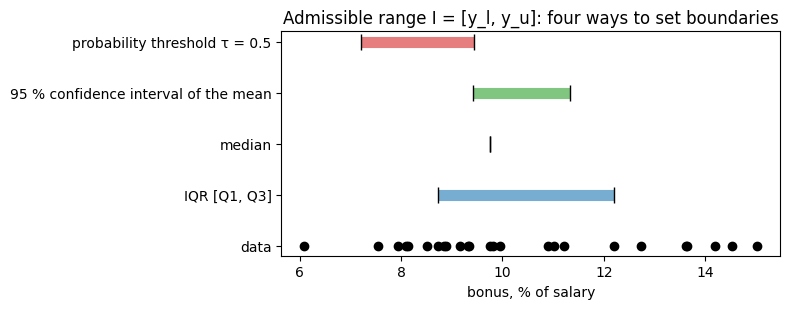

In [ ]:
# Comparable data: bonus (% of salary) in 25 comparable companies
comparables = rng.lognormal(mean=np.log(10), sigma=0.2, size=25)

Z = {0.90: 1.645, 0.95: 1.960, 0.99: 2.576}   # quantiles of the normal distribution


def interval_iqr(x):                       # 1) interquartile range (OECD recommendation)
    return float(np.quantile(x, 0.25)), float(np.quantile(x, 0.75))


def interval_median(x):                    # 2) median - the interval collapses to a point
    return float(np.median(x)), float(np.median(x))


def interval_ci(x, conf=0.95):             # 3) confidence interval for the mean
    h = Z[conf] * np.std(x, ddof=1) / np.sqrt(len(x))
    return float(np.mean(x) - h), float(np.mean(x) + h)


def interval_prob(x, tau=0.5, bins=8):     # 4) probability threshold: zone where density ≥ τ·max
    counts, edges = np.histogram(x, bins=bins)
    keep = np.flatnonzero(counts >= tau * counts.max())
    return float(edges[keep.min()]), float(edges[keep.max() + 1])


# Demonstrate
methods = {"IQR [Q1, Q3]": interval_iqr, "median": interval_median,
           "95 % confidence interval of the mean": interval_ci, "probability threshold τ = 0.5": interval_prob}
intervals = pd.DataFrame({m: f(comparables) for m, f in methods.items()}, index=["y_l", "y_u"]).T
intervals["width"] = intervals.y_u - intervals.y_l
print(intervals.round(2), "\n")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.scatter(comparables, np.zeros(len(comparables)), color="k", zorder=3)
for i, (m, f) in enumerate(methods.items(), start=1):
    lo, hi = f(comparables)
    ax.plot([lo, hi], [i, i], lw=8, alpha=0.6, solid_capstyle="butt")
    ax.plot([lo, hi], [i, i], "|", color="k", ms=12)
ax.set_yticks(range(len(methods) + 1))
ax.set_yticklabels(["data"] + list(methods))
ax.set_xlabel("bonus, % of salary")
ax.set_title("Admissible range I = [y_l, y_u]: four ways to set boundaries")
plt.tight_layout()
plt.show()

In [ ]:
# Compare intervals
I = interval_iqr(comparables)


# Check if in the interval
def in_interval(value, I):
    """Interval 1: any d ∈ I is admissible — no need to search for the “best” value."""
    return bool(I[0] <= value <= I[1])


print(f"I (IQR) = [{I[0]:.2f}, {I[1]:.2f}]")
for b in (9.5, 10.5, 14.0):
    print(f"  bonus {b:>5} % → admissible: {in_interval(b, I)}")


# Add cost check
def interval_by_cost(x, cost, w_max=0.25):
    """Interval 2: the width is inversely proportional to the cost of the error - quantiles [0.5−w, 0.5+w],
    w = w_max / cost."""
    w = min(w_max, w_max / cost)
    return float(np.quantile(x, 0.5 - w)), float(np.quantile(x, 0.5 + w))


print("\nCost of error C → interval:")
for cost in (1, 2, 5, 20):
    lo, hi = interval_by_cost(comparables, cost)
    print(f"  C = {cost:>2}: [{lo:.2f}, {hi:.2f}]  width {hi - lo:.2f}")


# Check data
def n_min(sd, margin, conf=0.95):
    """Interval 3: the minimum amount of data (according to the CLT)
    so that the error of the mean does not exceed the margin."""
    return int(np.ceil((Z[conf] * sd / margin) ** 2))


need = n_min(np.std(comparables, ddof=1), margin=0.06 * np.median(comparables))
print(f"\nData: n = {len(comparables)}, required n_min = {need} →",
      "decision allowed" if len(comparables) >= need else "ESCALATION: insufficient data, need director or more data")

I (IQR) = [8.72, 12.21]
  bonus   9.5 % → admissible: True
  bonus  10.5 % → admissible: True
  bonus  14.0 % → admissible: False

Cost of error C → interval:
  C =  1: [8.72, 12.21]  width 3.49
  C =  2: [9.16, 10.91]  width 1.75
  C =  5: [9.34, 9.84]  width 0.50
  C = 20: [9.63, 9.77]  width 0.14

Data: n = 25, required n_min = 67 → ESCALATION: insufficient data, need director or more data


## 4. Acceptable Risk (Definitions 8–9, Risk Axioms 1–4)

A decision affects different stakeholders with different interests, so risk is a **vector** $R(d)=(R_1,\dots,R_k)$, with a component per stakeholder, rather than a single number. Each component is measured by expected losses, VaR, or CVaR; a decision is risk-admissible if $R_i(d)\le R_i^{max}$ for all $i$.

- **Risk 1 (unconditional safety priority)** — stakeholders are ranked; risk for those with higher priorities is minimized lexicographically (life and dignity are prioritized over economic efficiency).
- **Risk 2 (probabilistic nature of guarantees)** — $P(R_1(d)\le R_1^{max})\ge 1-\delta$, where $\delta$ is explicitly declared and approved by stakeholders. With a VaR of level $\alpha$, this is the same as $\delta=1-\alpha$.
- **Risk 3 (prohibition of unjustified sacrifice)** — a stakeholder's threshold cannot be exceeded if there is an alternative that reduces their risk without violating the thresholds of others.
- **Risk 4 (accounting for tail risks)** — decisions with catastrophic potential require CVaR / extreme value theory, not variance-based measures (an example in the article is Dutch dams designed for a "one-in-10,000-year" event).

In the example, employee losses depend, among other things, on the $PSE_{inadm}$ chosen policy: discriminatory selection creates the risk of lawsuits and dissatisfaction - thus, risk is associated with equality.

In [ ]:
STAKEHOLDERS = ["employees", "customers", "shareholders"]                   # order = security priority p
R_MAX = pd.Series({"employees": 3.5, "customers": 3.0, "shareholders": 8.0})  # R^max — set by the corporation

# Decision set D: selection policy + bonus amount (% of salary). None = escalation to director.
ESCALATE = "d0: escalation to director"
DECISIONS = {
    "d1: biased,  bonus 10 %": dict(policy=policy_biased,  bonus=10.0),
    "d2: unaware, bonus 10 %": dict(policy=policy_unaware, bonus=10.0),
    "d3: causal,  bonus 10 %": dict(policy=policy_causal,  bonus=10.0),
    "d4: causal,  bonus 25 %": dict(policy=policy_causal,  bonus=25.0),
    "d5: causal,  bonus  4 %": dict(policy=policy_causal,  bonus=4.0),
    ESCALATE: None,
}


# Simulate losses
def simulate_losses(bonus, unfair, n=20_000, rng=rng):
    """Monte Carlo losses (conventional units) for each stakeholder in decision d.
    unfair — PSE_inadm policy: the more decisions affected by discrimination,
    the higher the risk of lawsuits and dissatisfaction.."""
    shock = rng.standard_t(df=3, size=n)                                              # heavy-tailed market shock
    shareholders = 0.8 * (bonus - 10) + 2.0 * shock                                   # budget overrun + shock
    employees = np.clip(0.5 * (12 - bonus), 0, None) + 12.0 * unfair + rng.normal(0, 1, n)   # employee turnover, lawsuits
    customers = 0.5 * np.clip(employees, 0, None) + rng.normal(0, 0.5, n)             # service outages due to
                                                                                      # staff turnover
    return pd.DataFrame({"employees": employees, "customers": customers, "shareholders": shareholders})


#Create risks vector
def risk_vector(losses, measure="VaR", alpha=0.95):
    """R(d) = (R_1, …, R_k): expected losses, VaR or CVaR (expected shortfall) for each stakeholder."""
    if measure == "expected":
        return losses.mean()
    var = losses.quantile(alpha)
    if measure == "VaR":
        return var
    return pd.Series({c: losses[c][losses[c] >= var[c]].mean() for c in losses})    # CVaR


#Check thresholds
def risk_ok(R, r_max=R_MAX):
    """Definition 9: d is risk-admissible if R_i(d) ≤ R_i^max for all i."""
    return bool((R <= r_max).all())

# Demonstrate
LOSSES, RISK = {}, {}
for name, spec in DECISIONS.items():
    if spec is None:
        continue
    unfair = equality_report(spec["policy"])["PSE_inadm (all inadmissible paths)"]
    LOSSES[name] = simulate_losses(spec["bonus"], unfair)
    RISK[name] = risk_vector(LOSSES[name], "VaR")

risk_tab = pd.DataFrame(RISK).T
risk_tab["R ≤ R_max"] = [risk_ok(r) for _, r in risk_tab.iterrows()]
print("R_max:", R_MAX.to_dict())
risk_tab

R_max: {'employees': 3.5, 'customers': 3.0, 'shareholders': 8.0}


,employees,customers,shareholders,R ≤ R_max
"d1: biased, bonus 10 %",4.007,2.350,4.631,False
"d2: unaware, bonus 10 %",2.924,1.796,4.723,True
"d3: causal, bonus 10 %",2.630,1.661,4.700,True
"d4: causal, bonus 25 %",1.633,1.188,16.665,False
"d5: causal, bonus 4 %",5.642,3.187,-0.190,False


In [ ]:
# Risk 1: lexicographic priority - first we minimize the risk of employees, then clients, then shareholders
order = sorted(RISK, key=lambda d: tuple(RISK[d][s] for s in STAKEHOLDERS))
print("Lexicographical order by risk vector (priority: employees > customers > shareholders):")
for d in order:
    print("  ", d, "→", tuple(round(float(RISK[d][s]), 2) for s in STAKEHOLDERS))
risk_admissible = [d for d in order if risk_ok(RISK[d])]
print("First in this order among the risk-admissible:", risk_admissible[0] if risk_admissible else "—")

# Risk 2: probabilistic guarantee — P(R_1(d) ≤ R_1^max) ≥ 1 − δ, where δ is declared and approved by stakeholders
DELTA = 0.05
print(f"\nRisk 2 (δ = {DELTA}): the probability that employee losses will not exceed R_1^max")
for d, L in LOSSES.items():
    p = (L["employees"] <= R_MAX["employees"]).mean()
    print(f"  {d}: P = {p:.3f} → {'OK' if p >= 1 - DELTA else 'violation'}")


# Risk 3: prohibition of unjustified sacrifice
def unjustified_sacrifice(d, risk=RISK, r_max=R_MAX):
    """d is inadmissible if for some stakeholder i R_i(d) > R_i^max, and there is d′ with a smaller R_i,
    which does not violate the thresholds of the others."""
    for s in STAKEHOLDERS:
        if risk[d][s] > r_max[s]:
            alts = [d2 for d2 in risk if d2 != d and risk[d2][s] < risk[d][s]
                    and all(risk[d2][o] <= r_max[o] for o in STAKEHOLDERS if o != s)]
            if alts:
                best = min(alts, key=lambda d2: risk[d2][s])
                return f"yes, the sacrifice of «{s}» is unjustified, there is an alternative {best}"
    return "no"


print("\nRisk 3:")
for d in RISK:
    print(f"  {d}: an unjustified sacrifice? \n{unjustified_sacrifice(d)}")

Lexicographical order by risk vector (priority: employees > customers > shareholders):
   d4: causal,  bonus 25 % → (1.63, 1.19, 16.66)
   d3: causal,  bonus 10 % → (2.63, 1.66, 4.7)
   d2: unaware, bonus 10 % → (2.92, 1.8, 4.72)
   d1: biased,  bonus 10 % → (4.01, 2.35, 4.63)
   d5: causal,  bonus  4 % → (5.64, 3.19, -0.19)
First in this order among the risk-admissible: d3: causal,  bonus 10 %

Risk 2 (δ = 0.05): the probability that employee losses will not exceed R_1^max
  d1: biased,  bonus 10 %: P = 0.874 → violation
  d2: unaware, bonus 10 %: P = 0.987 → OK
  d3: causal,  bonus 10 %: P = 0.993 → OK
  d4: causal,  bonus 25 %: P = 1.000 → OK
  d5: causal,  bonus  4 %: P = 0.309 → violation

Risk 3:
  d1: biased,  bonus 10 %: an unjustified sacrifice? 
yes, the sacrifice of «employees» is unjustified, there is an alternative d3: causal,  bonus 10 %
  d2: unaware, bonus 10 %: an unjustified sacrifice? 
no
  d3: causal,  bonus 10 %: an unjustified sacrifice? 
no
  d4: causal,  bonus 2

              variance  VaR 99 %  CVaR 99 %  VaR 99.9 %
normal            3.00      4.03       4.61        5.35
Student t(3)      3.05      4.58       7.17       10.40


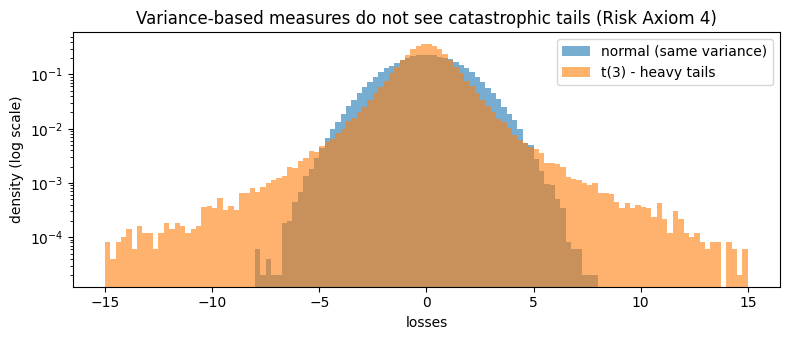

In [ ]:
#Demonstration

# Risk 4: same variance - different tails
n = 200_000
normal = rng.normal(0, np.sqrt(3), n)        # Gaussian shock with the same variance as t(3)
fat = rng.standard_t(df=3, size=n)           # Student's t-distribution, 3 degrees of freedom - "black swans"


# Tails
def tail_stats(x):
    v99 = np.quantile(x, 0.99)
    return {"variance": x.var(), "VaR 99 %": v99, "CVaR 99 %": x[x >= v99].mean(), "VaR 99.9 %": np.quantile(x, 0.999)}


print(pd.DataFrame({"normal": tail_stats(normal), "Student t(3)": tail_stats(fat)}).T.round(2))

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(-15, 15, 121)
ax.hist(normal, bins, alpha=0.6, density=True, label="normal (same variance)")
ax.hist(fat, bins, alpha=0.6, density=True, label="t(3) - heavy tails")
ax.set_yscale("log")
ax.set_xlabel("losses")
ax.set_ylabel("density (log scale)")
ax.set_title("Variance-based measures do not see catastrophic tails (Risk Axiom 4)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Integrated Admissibility Condition (Definition 10, Theorem 2)

$$D^*(t)=\{\,d\in D:\; F(d)\ge\theta \;\wedge\; E(d)=\text{true} \;\wedge\; d\in I_t \;\wedge\; R(d)\le R^{\max}\,\}$$

Four independent checks are connected by a conjunction. **Theorem 2:** Given Fairness Axiom 1 and a finite set of stakeholders $D^*(t)\ne\varnothing$, it always contains an escalation. If there is nothing else in $D^*(t)$ except escalation, the escalation protocol is triggered: no algorithmic decision satisfies all the normative requirements; a human is needed.

In [ ]:
# Evaluate management decision
def evaluate_decision(spec, data, config, I, r_max, eps=EPS, alpha=0.95):
    """Four checks for one decision. Escalation (spec=None) satisfies all by definition.."""
    if spec is None:
        return pd.Series({"F ≥ θ": True, "E(d)": True, "d ∈ I_t": True, "R ≤ R_max": True})
    y_hat, _ = run_policy(spec["policy"], data)
    F = justice_vector(data, y_hat, config)                                             # fairness
    det = is_deterministic(spec["policy"], data)                                        # equality
    pse = path_specific_effect(spec["policy"], data, True, INADMISSIBLE_MEDIATORS) if det else 1.0
    R = risk_vector(simulate_losses(spec["bonus"], pse), "VaR", alpha)                   # risk
    return pd.Series({"F ≥ θ": justice_ok(F, config),
                      "E(d)": bool(det and pse <= eps),
                      "d ∈ I_t": in_interval(spec["bonus"], I),                          # interval
                      "R ≤ R_max": risk_ok(R, r_max)})


# Admissible set
def admissible_set(data, config, I, r_max, decisions=DECISIONS):
    """D*(t) = {d : F ≥ θ ∧ E ∧ d ∈ I_t ∧ R ≤ R_max}."""
    tab = pd.DataFrame({name: evaluate_decision(spec, data, config, I, r_max)
                        for name, spec in decisions.items()}).T
    tab["d ∈ D*(t)"] = tab.all(axis=1)
    return tab

# Choose
def choose(tab, risk=RISK):
    """Choice within D*(t): among the admissible algorithmic decisions, we take the lexicographically smallest risk
    vector (Risk Axiom 1); if there are none, escalate."""
    cands = [d for d, ok in tab["d ∈ D*(t)"].items() if ok and d != ESCALATE]
    return min(cands, key=lambda d: tuple(risk[d][s] for s in STAKEHOLDERS)) if cands else ESCALATE


D_star = admissible_set(df, JURISDICTIONS["Jurisdiction A"], interval_iqr(comparables), R_MAX)
print("Theorem 2 - escalation is always in D*(t):", bool(D_star.loc[ESCALATE, "d ∈ D*(t)"]))
print("The chosen decision:", choose(D_star))
D_star

Theorem 2 - escalation is always in D*(t): True
The chosen decision: d3: causal,  bonus 10 %


,F ≥ θ,E(d),d ∈ I_t,R ≤ R_max,d ∈ D*(t)
"d1: biased, bonus 10 %",False,False,True,False,False
"d2: unaware, bonus 10 %",True,False,True,True,False
"d3: causal, bonus 10 %",True,True,True,True,True
"d4: causal, bonus 25 %",True,True,False,False,False
"d5: causal, bonus 4 %",True,True,False,False,False
d0: escalation to director,True,True,True,True,True


### Time Interval: Checkpoints and Escalation

Every month, the system receives new data and re-checks $V(d_t)\ge\theta\wedge R(d_t)\le R^{max}\wedge d_t\in I_t$. In the simulation, the market drifts (competitors' bonuses rise), and in one month, there is too little comparable data (Axiom Interval 3). We observe how $D^*(t)$ changes and when the system hands the decision over to the director.

In [ ]:
# Check per month
config = JURISDICTIONS["Jurisdiction A"]
log = []
for t in range(12):                                         # 12 monthly checkpoints T = {t0, …, t11}
    rng_t = np.random.default_rng(100 + t)
    data_t = df.sample(n=10000, random_state=100 + t)        # new data for the month
    market_median = 10 + 0.45 * t                           # market drift: competitors' bonuses are rising
    n_comp = 20 if t == 2 else 200                          # there is little comparable data in month 2
    comp_t = rng_t.lognormal(np.log(market_median), 0.2, size=n_comp)
    I_t = interval_iqr(comp_t)
    enough = len(comp_t) >= n_min(np.std(comp_t, ddof=1), margin=0.06 * np.median(comp_t))
    tab = admissible_set(data_t, config, I_t, R_MAX)
    if not enough:                                          # Interval 3 Axiom: Little data → only escalation
        tab.loc[tab.index != ESCALATE, "d ∈ D*(t)"] = False
    log.append({"t": t, "I_t": f"[{I_t[0]:.1f}, {I_t[1]:.1f}]", "n ≥ n_min": enough,
                **tab["d ∈ D*(t)"].to_dict(), "choice": choose(tab)})
log = pd.DataFrame(log).set_index("t")
log

,I_t,n ≥ n_min,"d1: biased, bonus 10 %","d2: unaware, bonus 10 %","d3: causal, bonus 10 %","d4: causal, bonus 25 %","d5: causal, bonus 4 %",d0: escalation to director,choice
t,,,,,,,,,
0,"[8.9, 11.7]",True,False,False,True,False,False,True,"d3: causal, bonus 10 %"
1,"[8.8, 12.1]",True,False,False,True,False,False,True,"d3: causal, bonus 10 %"
2,"[9.7, 13.4]",False,False,False,False,False,False,True,d0: escalation to director
3,"[9.9, 12.9]",True,False,False,True,False,False,True,"d3: causal, bonus 10 %"
4,"[10.4, 13.5]",True,False,False,False,False,False,True,d0: escalation to director
5,"[10.8, 14.3]",True,False,False,False,False,False,True,d0: escalation to director
6,"[11.3, 14.5]",True,False,False,False,False,False,True,d0: escalation to director
7,"[11.5, 15.0]",True,False,False,False,False,False,True,d0: escalation to director
8,"[12.4, 15.7]",True,False,False,False,False,False,True,d0: escalation to director


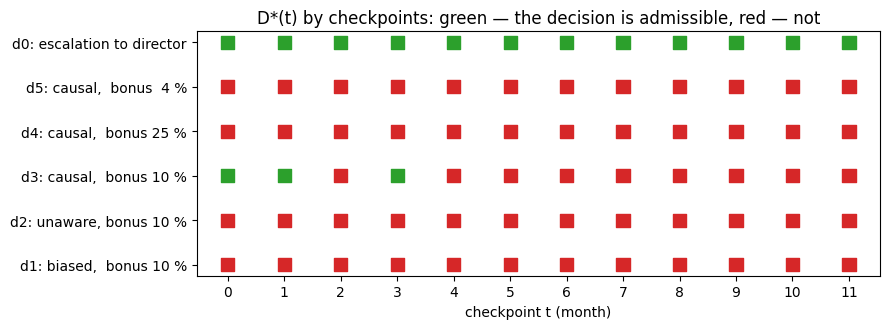

Months in which the escalation protocol was triggered: [2, 4, 5, 6, 7, 8, 9, 10, 11]


In [ ]:
# Demonstrate
names = list(DECISIONS)
fig, ax = plt.subplots(figsize=(9, 3.4))
for i, d in enumerate(names):
    ok = log[d].values.astype(bool)
    ax.scatter(log.index, [i] * len(log), c=np.where(ok, "tab:green", "tab:red"), s=90, marker="s")
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
ax.set_xticks(log.index)
ax.set_xlabel("checkpoint t (month)")
ax.set_title("D*(t) by checkpoints: green — the decision is admissible, red — not")
plt.tight_layout()
plt.show()

first = log.index[log["choice"] == ESCALATE].tolist()
print("Months in which the escalation protocol was triggered:", first)

What happened: in months 0, 1 and 3 the only admissible algorithmic decision is d3; in month 2 there are fewer than $n_{min}$ comparable data points (Interval 3), and the system is obliged to escalate; from month 4 onwards the market has shifted, the fixed 10% bonus has dropped out of $I_t$, and only escalation remains in $D^*(t)$. The formal structure itself signals to the director that a decision parameter (the bonus size) needs to be revised — the analogue of judicial deference discussed in Section 8.2 of the paper.

## 6. Extensibility: Adding a New Standard

Section 9 of the article: constraints constructed using a unified procedure are **composed by conjunction**, so a new standard is added without revising existing ones, and Theorem 2 is preserved if the escalation trivially satisfies the new constraint. An example is the duty of loyalty as the absence of an inadmissible causal path "private interest of the decision maker → decision."

In [ ]:
# Every decision has a proposer. A conflict of interest arises when the proposer personally benefits
# from the decision: a causal path "private interest -> decision", which the duty of loyalty forbids.
PROPOSED_BY = {
    "d1: biased,  bonus 10 %": ("HR committee", False),
    "d2: unaware, bonus 10 %": ("HR committee", False),
    "d3: causal,  bonus 10 %": ("HR committee", False),
    "d4: causal,  bonus 25 %": ("a manager who would receive the bonus himself", True),   # conflict of interest
    "d5: causal,  bonus  4 %": ("HR committee", False),
    ESCALATE:                  ("—", False),
}
assert set(PROPOSED_BY) == set(DECISIONS), "PROPOSED_BY keys must match DECISIONS keys exactly"


# Check private interests
def loyalty_ok(name):
    """Duty of loyalty = no causal path from the proposer's private interest to the decision.
    Escalation passes trivially: a human director, not the interested party, decides."""
    proposer, conflict = PROPOSED_BY[name]
    return not conflict


# Check extended
extended = D_star.drop(columns="d ∈ D*(t)")
extended["loyalty"] = [loyalty_ok(n) for n in extended.index]   # new constraint = one more column
extended["d ∈ D*(t)"] = extended.all(axis=1)                    # conjunction; earlier checks untouched
print("Theorem 2 still holds:", bool(extended.loc[ESCALATE, "d ∈ D*(t)"]))
extended

Theorem 2 still holds: True


,F ≥ θ,E(d),d ∈ I_t,R ≤ R_max,loyalty,d ∈ D*(t)
"d1: biased, bonus 10 %",False,False,True,False,True,False
"d2: unaware, bonus 10 %",True,False,True,True,True,False
"d3: causal, bonus 10 %",True,True,True,True,True,True
"d4: causal, bonus 25 %",True,True,False,False,False,False
"d5: causal, bonus 4 %",True,True,False,False,True,False
d0: escalation to director,True,True,True,True,True,True


## References

*   Becker B., Kohavi R. Adult [Dataset]. UCI Machine Learning Repository, 1996. DOI: 10.24432/C5XW20.
*   Chouldechova A. Fair prediction with disparate impact: A study of bias in recidivism prediction instruments. Big Data, 2017, vol. 5, no. 2, pp. 153-163. DOI: 10.1089/big.2016.0047.
*   Kleinberg J., Mullainathan S., Raghavan M. Inherent trade-offs in the fair determination of risk scores. In Proc. of the 8th Innovations in Theoretical Computer Science Conference (ITCS 2017), LIPIcs, vol. 67, 2017, pp. 43:1-43:23. DOI: 10.4230/LIPIcs.ITCS.2017.43.
*   Nabi R., Shpitser I. Fair inference on outcomes. In Proc. of the 32nd AAAI Conference on Artificial Intelligence (AAAI-18), 2018, pp. 1931-1940. DOI: 10.1609/aaai.v32i1.11553.
*   OECD. OECD Transfer Pricing Guidelines for Multinational Enterprises and Tax Administrations 2022. Paris, OECD Publishing, 2022. DOI: 10.1787/0e655865-en.
*   Plečko D., Bareinboim E. Causal fairness analysis: A causal toolkit for fair machine learning. Foundations and Trends in Machine Learning, 2024, vol. 17, no. 3, pp. 304-589. DOI: 10.1561/2200000106.
*   Van Dantzig D. Economic decision problems for flood prevention. Econometrica, 1956, vol. 24, no. 3, pp. 276-287.
